# 03 - Dataset Creation

This notebook creates windowed datasets for each feature group.

## Objectives
- Preprocess raw data
- Add technical indicators
- Create sliding window sequences
- Split into train/validation/test sets
- Save datasets for training

In [1]:
import sys
from pathlib import Path

# Fix statistics module shadowing issue - MUST be done before any imports that use statistics
for mod_name in list(sys.modules.keys()):
    if mod_name == 'statistics' or mod_name.startswith('statistics.'):
        del sys.modules[mod_name]

# Get project root
project_root = Path.cwd().parent if 'notebooks' in str(Path.cwd()) else Path.cwd()

# Temporarily remove project paths that contain 'statistics' folder during imports
original_path = sys.path.copy()
sys.path = [p for p in sys.path if not (Path(p) / 'statistics').exists() or 'site-packages' in p]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns  # Import seaborn while paths are filtered

# Now restore path and add project root for our imports
sys.path = original_path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.config import Config
from src.data.loader import DataLoader
from src.features.indicators import add_all_indicators
from src.data.window_generator import create_sequences

%matplotlib inline

In [2]:
# Load configuration
config = Config.load()

# Display feature groups
print("Feature Groups:")
for group_name, group_config in config.feature_groups.items():
    if 'features' not in group_config:
        continue
    print(f"\n{group_name}:")
    for f in group_config.get('features', []):
        print(f"  - {f}")

Feature Groups:

group0_ohlcv:
  - Open
  - High
  - Low
  - Close
  - Volume

group1_momentum:
  - Open
  - High
  - Low
  - Close
  - Volume
  - RSI
  - Stochastic_K
  - Stochastic_D

group2_trend:
  - Open
  - High
  - Low
  - Close
  - Volume
  - SMA
  - EMA
  - ADX
  - MACD
  - MACD_Signal
  - MACD_Histogram

group3_volatility:
  - Open
  - High
  - Low
  - Close
  - Volume
  - ATR
  - BB_Upper
  - BB_Lower
  - BB_PercentB

group4_all:
  - Open
  - High
  - Low
  - Close
  - Volume
  - RSI
  - Stochastic_K
  - Stochastic_D
  - SMA
  - EMA
  - ADX
  - MACD
  - MACD_Signal
  - MACD_Histogram
  - ATR
  - BB_Upper
  - BB_Lower
  - BB_PercentB


In [3]:
# Configuration
assets = config.get_all_assets()

WINDOW_SIZE = config.base.get('window_size', 60)
HORIZON = config.base.get('horizon', 1)

print(f"Assets: {assets}")
print(f"Window Size: {WINDOW_SIZE}")
print(f"Forecast Horizon: {HORIZON}")

Assets: ['crudeoil', 'gold', 'bitcoin', 'ethereum', 'apple', 'microsoft', 'eurusd', 'usdjpy', 'nasdaq', 'sp500']
Window Size: 60
Forecast Horizon: 1


## 1. Load and Preprocess Data

In [4]:
# Load raw data for all assets
loader = DataLoader(config)
df_raw = {}
for asset in assets:
    df_raw[asset] = loader.load(asset)
    print(f"{asset} - Raw data shape: {df_raw[asset].shape}")
    print(f"{asset} - Date range: {df_raw[asset].index.min()} to {df_raw[asset].index.max()}")

2026-02-02 03:26:22 | INFO | Loading data from C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\data\raw\commodity\crudeoil\CrudeOil_daily.csv
2026-02-02 03:26:22 | INFO | Loaded 4024 rows with columns: ['Open', 'High', 'Low', 'Close', 'Volume']
crudeoil - Raw data shape: (4024, 5)
crudeoil - Date range: 2010-01-04 00:00:00 to 2025-12-31 00:00:00
2026-02-02 03:26:22 | INFO | Loading data from C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\data\raw\commodity\gold\Gold_daily.csv
2026-02-02 03:26:22 | INFO | Loaded 4023 rows with columns: ['Open', 'High', 'Low', 'Close', 'Volume']
gold - Raw data shape: (4023, 5)
gold - Date range: 2010-01-04 00:00:00 to 2025-12-31 00:00:00
2026-02-02 03:26:22 | INFO | Loading data from C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\data\raw\crypto\bitcoin\Bitcoin_daily.csv
2026-02-02 03:26:22 | INFO | Loaded 4124 rows with columns: ['Open', 'High', 'Low', 'Close', 'Volume']
bitcoin - Raw data shape: (4124,

In [5]:
# Add all technical indicators for all assets
df_indicators = {}
for asset in assets:
    df_indicators[asset] = add_all_indicators(df_raw[asset].copy())
    print(f"{asset} - Shape after indicators: {df_indicators[asset].shape}")
    print(f"{asset} - New columns: {len(df_indicators[asset].columns) - len(df_raw[asset].columns)}")

crudeoil - Shape after indicators: (4024, 18)
crudeoil - New columns: 13
gold - Shape after indicators: (4023, 18)
gold - New columns: 13
bitcoin - Shape after indicators: (4124, 18)
bitcoin - New columns: 13
ethereum - Shape after indicators: (2975, 18)
ethereum - New columns: 13
apple - Shape after indicators: (4024, 18)
apple - New columns: 13
microsoft - Shape after indicators: (4024, 18)
microsoft - New columns: 13
eurusd - Shape after indicators: (4165, 18)
eurusd - New columns: 13
usdjpy - Shape after indicators: (4165, 18)
usdjpy - New columns: 13
nasdaq - Shape after indicators: (4024, 18)
nasdaq - New columns: 13
sp500 - Shape after indicators: (4024, 18)
sp500 - New columns: 13


In [6]:
# Drop rows with NaN values (from indicator lookback)
df_clean = {}
for asset in assets:
    df_clean[asset] = df_indicators[asset].dropna()
    print(f"{asset} - Shape after dropping NaN: {df_clean[asset].shape}")
    print(f"{asset} - Rows dropped: {len(df_indicators[asset]) - len(df_clean[asset])}")

crudeoil - Shape after dropping NaN: (3991, 18)
crudeoil - Rows dropped: 33
gold - Shape after dropping NaN: (3990, 18)
gold - Rows dropped: 33
bitcoin - Shape after dropping NaN: (4091, 18)
bitcoin - Rows dropped: 33
ethereum - Shape after dropping NaN: (2942, 18)
ethereum - Rows dropped: 33
apple - Shape after dropping NaN: (3991, 18)
apple - Rows dropped: 33
microsoft - Shape after dropping NaN: (3991, 18)
microsoft - Rows dropped: 33
eurusd - Shape after dropping NaN: (4132, 18)
eurusd - Rows dropped: 33
usdjpy - Shape after dropping NaN: (4132, 18)
usdjpy - Rows dropped: 33
nasdaq - Shape after dropping NaN: (3991, 18)
nasdaq - Rows dropped: 33
sp500 - Shape after dropping NaN: (3991, 18)
sp500 - Rows dropped: 33


## 2. Create Datasets for Each Feature Group

In [8]:
def create_dataset_for_group(df, group_name, feature_cols, target_col='Close'):
    """
    Create train/val/test datasets for a feature group.
    
    Args:
        df: DataFrame with all features
        group_name: Name of the feature group
        feature_cols: List of feature column names
        target_col: Target column name
        
    Returns:
        Dictionary with train/val/test data
    """
    print(f"\n{'='*50}")
    print(f"Creating dataset for: {group_name}")
    print(f"Features: {len(feature_cols)}")
    print(f"{'='*50}")
    
    # Filter columns that exist
    valid_cols = [c for c in feature_cols if c in df.columns]
    if len(valid_cols) != len(feature_cols):
        missing = set(feature_cols) - set(valid_cols)
        print(f"Warning: Missing columns: {missing}")
    
    # Ensure target is in columns
    all_cols = valid_cols + [target_col] if target_col not in valid_cols else valid_cols
    
    # Select features
    df_features = df[all_cols].copy()
    
    # Split data first (time series - no shuffle)
    train_ratio = config.base.get('train_ratio', 0.8)
    val_ratio = config.base.get('val_ratio', 0.1)
    
    n_samples = len(df_features)
    train_end = int(n_samples * train_ratio)
    val_end = int(n_samples * (train_ratio + val_ratio))
    
    df_train = df_features.iloc[:train_end]
    df_val = df_features.iloc[train_end:val_end]
    df_test = df_features.iloc[val_end:]
    
    # Scale features (fit on train, transform all)
    scaler = MinMaxScaler()
    train_scaled = scaler.fit_transform(df_train)
    val_scaled = scaler.transform(df_val)
    test_scaled = scaler.transform(df_test)
    
    # Create windows using the standalone function
    target_idx = all_cols.index(target_col)
    
    X_train, y_train = create_sequences(train_scaled, WINDOW_SIZE, HORIZON, target_idx)
    X_val, y_val = create_sequences(val_scaled, WINDOW_SIZE, HORIZON, target_idx)
    X_test, y_test = create_sequences(test_scaled, WINDOW_SIZE, HORIZON, target_idx)
    
    print(f"\nTotal samples: {len(df_features)}")
    print(f"X shape: {X_train.shape}")
    print(f"y shape: {y_train.shape}")
    
    print(f"\nSplit sizes:")
    print(f"  Train: {len(X_train)} ({len(X_train)/(len(X_train)+len(X_val)+len(X_test))*100:.1f}%)")
    print(f"  Val: {len(X_val)} ({len(X_val)/(len(X_train)+len(X_val)+len(X_test))*100:.1f}%)")
    print(f"  Test: {len(X_test)} ({len(X_test)/(len(X_train)+len(X_val)+len(X_test))*100:.1f}%)")
    
    return {
        'X_train': X_train, 'y_train': y_train,
        'X_val': X_val, 'y_val': y_val,
        'X_test': X_test, 'y_test': y_test,
        'scaler': scaler,
        'feature_cols': all_cols
    }

In [9]:
# Create datasets for each asset and group
datasets = {}
for asset in assets:
    datasets[asset] = {}
    for group_name, group_config in config.feature_groups.items():
        # Skip entries that don't have features (like indicators definitions)
        if 'features' not in group_config:
            continue
            
        features = group_config['features']
        
        datasets[asset][group_name] = create_dataset_for_group(df_clean[asset], group_name, features)


Creating dataset for: group0_ohlcv
Features: 5

Total samples: 3991
X shape: (3132, 60, 5)
y shape: (3132,)

Split sizes:
  Train: 3132 (82.2%)
  Val: 339 (8.9%)
  Test: 340 (8.9%)

Creating dataset for: group1_momentum
Features: 8

Total samples: 3991
X shape: (3132, 60, 8)
y shape: (3132,)

Split sizes:
  Train: 3132 (82.2%)
  Val: 339 (8.9%)
  Test: 340 (8.9%)

Creating dataset for: group2_trend
Features: 11

Total samples: 3991
X shape: (3132, 60, 11)
y shape: (3132,)

Split sizes:
  Train: 3132 (82.2%)
  Val: 339 (8.9%)
  Test: 340 (8.9%)

Creating dataset for: group3_volatility
Features: 9

Total samples: 3991
X shape: (3132, 60, 9)
y shape: (3132,)

Split sizes:
  Train: 3132 (82.2%)
  Val: 339 (8.9%)
  Test: 340 (8.9%)

Creating dataset for: group4_all
Features: 18

Total samples: 3991
X shape: (3132, 60, 18)
y shape: (3132,)

Split sizes:
  Train: 3132 (82.2%)
  Val: 339 (8.9%)
  Test: 340 (8.9%)

Creating dataset for: group0_ohlcv
Features: 5

Total samples: 3990
X shape: (3

## 3. Visualize Dataset Characteristics

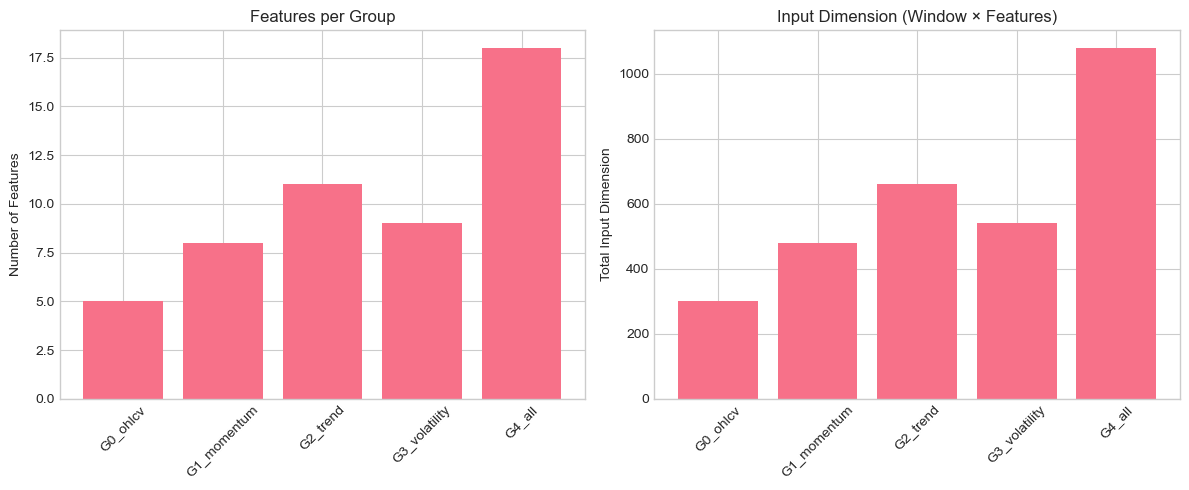

In [10]:
# Compare dataset sizes for apple
sample_asset = 'apple'
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Number of features per group
group_names = list(datasets[sample_asset].keys())
n_features = [len(datasets[sample_asset][g]['feature_cols']) for g in group_names]

axes[0].bar(range(len(group_names)), n_features)
axes[0].set_xticks(range(len(group_names)))
axes[0].set_xticklabels([g.replace('group', 'G') for g in group_names], rotation=45)
axes[0].set_ylabel('Number of Features')
axes[0].set_title('Features per Group')

# Input dimension (window_size * features)
input_dims = [datasets[sample_asset][g]['X_train'].shape[1] * datasets[sample_asset][g]['X_train'].shape[2] for g in group_names]

axes[1].bar(range(len(group_names)), input_dims)
axes[1].set_xticks(range(len(group_names)))
axes[1].set_xticklabels([g.replace('group', 'G') for g in group_names], rotation=45)
axes[1].set_ylabel('Total Input Dimension')
axes[1].set_title('Input Dimension (Window × Features)')

plt.tight_layout()
plt.show()

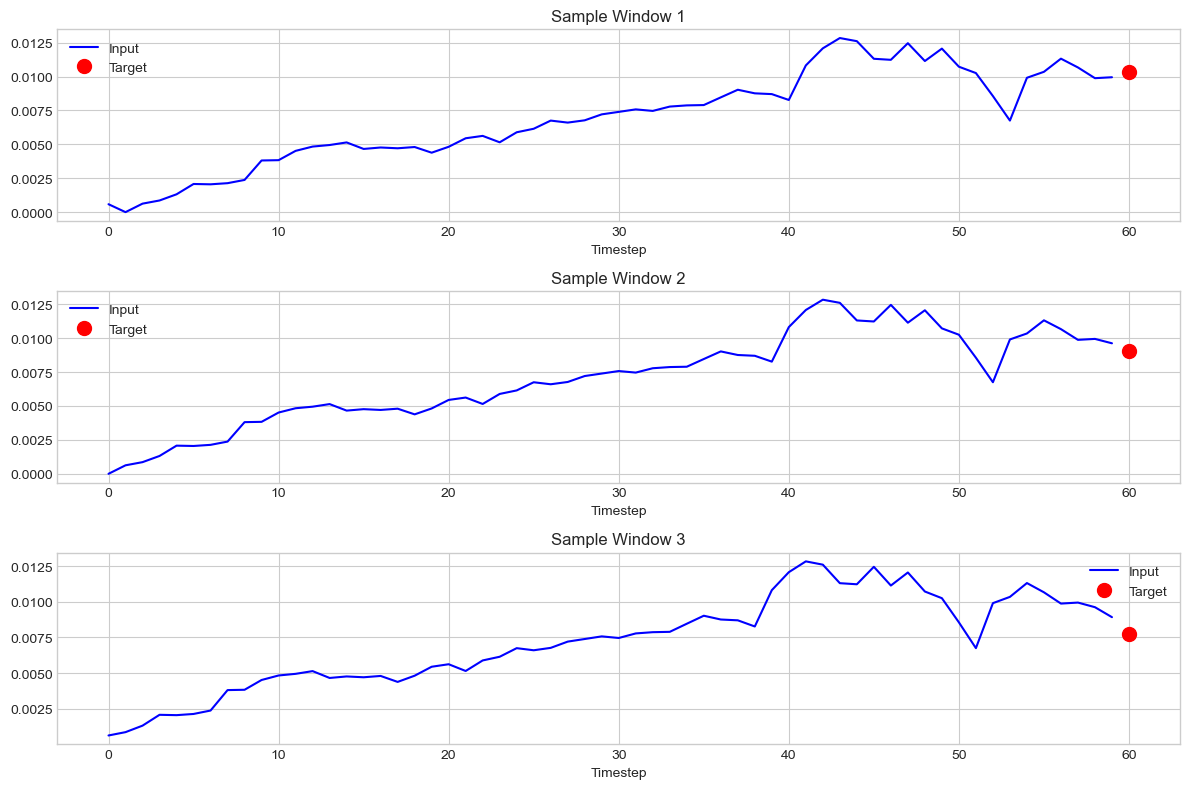

In [11]:
# Visualize sample windows from group5_all for apple
sample_asset = 'apple'
sample_group = 'group4_all'
X_sample = datasets[sample_asset][sample_group]['X_train'][:3]
y_sample = datasets[sample_asset][sample_group]['y_train'][:3]

fig, axes = plt.subplots(3, 1, figsize=(12, 8))

for i in range(3):
    # Plot first feature (usually close price)
    axes[i].plot(range(WINDOW_SIZE), X_sample[i, :, 0], 'b-', label='Input')
    axes[i].plot(WINDOW_SIZE, y_sample[i], 'ro', markersize=10, label='Target')
    axes[i].set_title(f'Sample Window {i+1}')
    axes[i].legend()
    axes[i].set_xlabel('Timestep')

plt.tight_layout()
plt.show()

## 4. Save Datasets

In [12]:
import joblib

for asset in assets:
    asset_config = config.get_asset_config(asset)
    category = asset_config['category']
    for group_name, data in datasets[asset].items():
        output_dir = config.get_path('processed_data') / category / asset / group_name
        output_dir.mkdir(parents=True, exist_ok=True)
        print(f"Saving datasets for {asset} - {group_name} to: {output_dir}")
        
        # Save numpy arrays
        np.save(output_dir / f'X_train.npy', data['X_train'])
        np.save(output_dir / f'y_train.npy', data['y_train'])
        np.save(output_dir / f'X_val.npy', data['X_val'])
        np.save(output_dir / f'y_val.npy', data['y_val'])
        np.save(output_dir / f'X_test.npy', data['X_test'])
        np.save(output_dir / f'y_test.npy', data['y_test'])
        
        # Save scaler
        joblib.dump(data['scaler'], output_dir / f'scaler.pkl')
        
        # Save feature list
        with open(output_dir / f'features.txt', 'w') as f:
            for feat in data['feature_cols']:
                f.write(f"{feat}\n")
        
        print(f"  Saved {group_name}")

print("\nDataset creation complete!")

Saving datasets for crudeoil - group0_ohlcv to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\data\processed\commodity\crudeoil\group0_ohlcv
  Saved group0_ohlcv
Saving datasets for crudeoil - group1_momentum to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\data\processed\commodity\crudeoil\group1_momentum
  Saved group1_momentum
Saving datasets for crudeoil - group2_trend to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\data\processed\commodity\crudeoil\group2_trend
  Saved group2_trend
Saving datasets for crudeoil - group3_volatility to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\data\processed\commodity\crudeoil\group3_volatility
  Saved group3_volatility
Saving datasets for crudeoil - group4_all to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\data\processed\commodity\crudeoil\group4_all
  Saved group4_all
Saving datasets for gold - group0_ohlcv to: C:\Users\Nabeel\Desktop\New folder\ind

## 5. Summary

In [13]:
print("="*60)
print("DATASET CREATION SUMMARY")
print("="*60)
print(f"\nAssets: {assets}")
print(f"Window Size: {WINDOW_SIZE}")
print(f"Forecast Horizon: {HORIZON}")
for asset in assets:
    print(f"\nAsset: {asset}")
    print("Datasets created:")
    for group_name, data in datasets[asset].items():
        print(f"\n  {group_name}:")
        print(f"    Features: {len(data['feature_cols'])}")
        print(f"    X shape: {data['X_train'].shape[1:]}")
        print(f"    Train samples: {len(data['X_train'])}")
        print(f"    Val samples: {len(data['X_val'])}")
        print(f"    Test samples: {len(data['X_test'])}")

DATASET CREATION SUMMARY

Assets: ['EURUSD', 'GBPUSD', 'AAPLUSUSD', 'TSLAUSUSD', 'BTCUSD', 'ETHUSD']
Window Size: 60
Forecast Horizon: 1

Asset: EURUSD
Datasets created:

  group0_ohlcv:
    Features: 5
    X shape: (60, 5)
    Train samples: 5516
    Val samples: 1135
    Test samples: 1136

  group1_momentum:
    Features: 8
    X shape: (60, 8)
    Train samples: 5516
    Val samples: 1135
    Test samples: 1136

  group2_trend:
    Features: 8
    X shape: (60, 8)
    Train samples: 5516
    Val samples: 1135
    Test samples: 1136

  group3_volatility:
    Features: 9
    X shape: (60, 9)
    Train samples: 5516
    Val samples: 1135
    Test samples: 1136

  group4_macd:
    Features: 8
    X shape: (60, 8)
    Train samples: 5516
    Val samples: 1135
    Test samples: 1136

  group5_all:
    Features: 18
    X shape: (60, 18)
    Train samples: 5516
    Val samples: 1135
    Test samples: 1136

Asset: GBPUSD
Datasets created:

  group0_ohlcv:
    Features: 5
    X shape: (60, 5